# Thực hiện thống kê mô tả trên tập dữ liệu về bệnh tiểu đường

# LAB 1.1.4 – THỐNG KÊ MÔ TẢ DỮ LIỆU BỆNH TIỂU ĐƯỜNG

**Môn học:** Phân tích khám phá dữ liệu (EDA)

**Đề bài:** Thực hiện thống kê mô tả trên tập dữ liệu về bệnh tiểu đường.

**Dataset:** Pima Indians Diabetes.

## Mục tiêu
- Khám phá cấu trúc tập dữ liệu.
- Kiểm tra dữ liệu thiếu và trùng lặp.
- Tính Mean, Median, Mode, Variance, Standard Deviation.
- Tính Min, Max, Range, Percentile, Q1, Q2, Q3 và IQR.
- Trực quan hóa dữ liệu bằng Histogram, Boxplot, Countplot.
- Phân tích sự phân bố các thuộc tính.
- Đưa ra nhận xét và kết luận.



## 1. Import thư viện và đọc CSV

In [13]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

filepath = Path("diabetes.csv")

if not filepath.exists():
    filepath = Path("diabetes (1).csv")

if not filepath.exists():
    raise FileNotFoundError(
        "Hãy đặt diabetes.csv cùng thư mục với notebook."
    )

df = pd.read_csv(filepath)

print("Dataset:", filepath.name)
print("Kích thước:", df.shape)

display(df.head(10))


Dataset: diabetes (1).csv
Kích thước: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


## 2. Kiểm tra cấu trúc dataset

In [14]:

print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\nDanh sách cột:")
print(df.columns.tolist())

print("\nThông tin dữ liệu:")
df.info()


Số dòng: 768
Số cột: 9

Danh sách cột:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## 3. Kiểm tra dữ liệu thiếu, trùng lập và số giá trị khác nhau

In [15]:

quality = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Giá trị thiếu (NaN)": df.isna().sum(),
    "Tỷ lệ thiếu (%)": (
        df.isna().mean() * 100
    ).round(2),
    "Giá trị duy nhất": df.nunique()
})

display(quality)

print(
    "Số dòng trùng lặp hoàn toàn:",
    df.duplicated().sum()
)


,Kiểu dữ liệu,Giá trị thiếu (NaN),Tỷ lệ thiếu (%),Giá trị duy nhất
Pregnancies,int64,0,0.0,17
Glucose,int64,0,0.0,136
BloodPressure,int64,0,0.0,47
SkinThickness,int64,0,0.0,51
Insulin,int64,0,0.0,186
BMI,float64,0,0.0,248
DiabetesPedigreeFunction,float64,0,0.0,517
Age,int64,0,0.0,52
Outcome,int64,0,0.0,2


Số dòng trùng lặp hoàn toàn: 0


## 4. Kiểm tra giá trị bằng 0 bất thường

In [16]:

measurement_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_summary = pd.DataFrame({
    "Số giá trị 0": (
        df[measurement_cols] == 0
    ).sum(),

    "Tỷ lệ (%)": (
        (df[measurement_cols] == 0).mean() * 100
    ).round(2)
}).sort_values(
    "Số giá trị 0",
    ascending=False
)

display(zero_summary)


,Số giá trị 0,Tỷ lệ (%)
Insulin,374,48.70
SkinThickness,227,29.56
BloodPressure,35,4.56
BMI,11,1.43
Glucose,5,0.65


### Nhận xét các giá trị
#### Dataset không chứa giá trị thiếu NaN và không có dòng trùng lặp hoàn toàn.

#### Tuy nhiên, một số thuộc tính chứa nhiều giá trị bằng 0 bất thường.

#### Đặc biệt:
- Insulin có 374 giá trị 0, chiếm 48,70%.
- SkinThickness có 227 giá trị 0, chiếm 29,56%.

#### Các giá trị này có thể ảnh hưởng đến các chỉ số thống kê như Mean, Median và Standard Deviation.

#### Do đó, cần xem xét chất lượng dữ liệu trước khi thực hiện các phân tích chuyên sâu.

## 5. Phân tích phân bố nhãn Outcome

,Số mẫu,Tỷ lệ (%)
Outcome,,
0,500,65.1
1,268,34.9


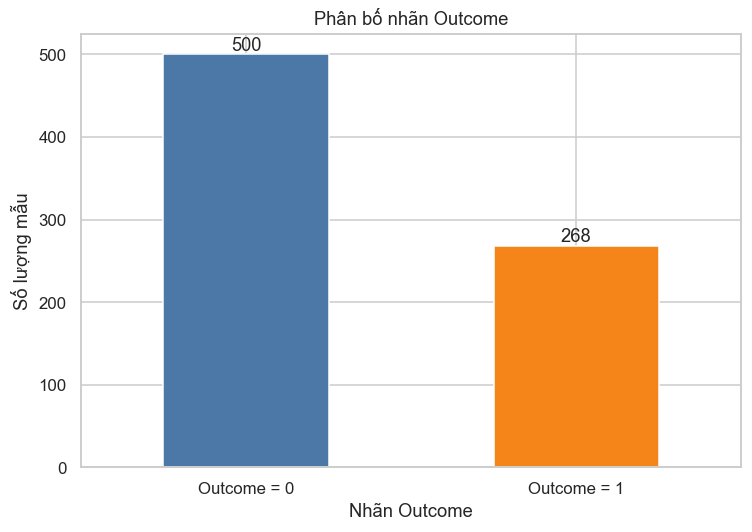

In [17]:

label_counts = df["Outcome"].value_counts().sort_index()

label_df = pd.DataFrame({
    "Số mẫu": label_counts,
    "Tỷ lệ (%)": (
        100 * label_counts / len(df)
    ).round(2)
})

display(label_df)

ax = label_counts.rename(
    index={
        0: "Outcome = 0",
        1: "Outcome = 1"
    }
).plot(
    kind="bar",
    figsize=(7, 5),
    color=["#4C78A8", "#F58518"],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container)

ax.set_title("Phân bố nhãn Outcome")
ax.set_xlabel("Nhãn Outcome")
ax.set_ylabel("Số lượng mẫu")

plt.tight_layout()
plt.show()


## Nhận xét phân bố nhãn Outcome
#### Dataset có tổng cộng 768 mẫu.

#### Trong đó:
- Outcome = 0: 500 mẫu, chiếm 65,10%.
- Outcome = 1: 268 mẫu, chiếm 34,90%.

#### Nhóm Outcome = 0 có số lượng lớn hơn nhóm Outcome = 1.

#### Phân bố dữ liệu giữa hai nhóm có sự chênh lệch, tuy nhiên cả hai nhóm đều có số lượng mẫu đáng kể để thực hiện thống kê mô tả.

## 6. Bảng thống kê mô tả đầy đủ

In [18]:

features = [
    c for c in df.columns
    if c != "Outcome"
]

X = df[features].copy()

# Hàm tìm Mode
def get_modes(series):
    vals = series.mode(dropna=True)
    return ", ".join(f"{v:g}" for v in vals)

# Tạo bảng thống kê
summary = pd.DataFrame(index=features)

summary["Count"] = X.count()

summary["Mean"] = X.mean()

summary["Median (Q2)"] = X.median()

summary["Mode"] = X.apply(get_modes)

summary["Variance (sample)"] = X.var(ddof=1)

summary["Std (sample)"] = X.std(ddof=1)

summary["Min"] = X.min()

summary["Max"] = X.max()

summary["Range"] = X.max() - X.min()

summary["Percentile 60%"] = X.quantile(0.60)

summary["Q1 (25%)"] = X.quantile(0.25)

summary["Q2 (50%)"] = X.quantile(0.50)

summary["Q3 (75%)"] = X.quantile(0.75)

summary["IQR"] = (
    summary["Q3 (75%)"] -
    summary["Q1 (25%)"]
)

display(summary.round(3))


,Count,Mean,Median (Q2),Mode,Variance (sample),Std (sample),Min,Max,Range,Percentile 60%,Q1 (25%),Q2 (50%),Q3 (75%),IQR
Pregnancies,768,3.845,3.000,1,11.354,3.370,0.000,17.00,17.000,4.000,1.000,3.000,6.000,5.000
Glucose,768,120.895,117.000,"99, 100",1022.248,31.973,0.000,199.00,199.000,125.000,99.000,117.000,140.250,41.250
BloodPressure,768,69.105,72.000,70,374.647,19.356,0.000,122.00,122.000,74.000,62.000,72.000,80.000,18.000
SkinThickness,768,20.536,23.000,0,254.473,15.952,0.000,99.00,99.000,27.000,0.000,23.000,32.000,32.000
Insulin,768,79.799,30.500,0,13281.180,115.244,0.000,846.00,846.000,72.200,0.000,30.500,127.250,127.250
BMI,768,31.993,32.000,32,62.160,7.884,0.000,67.10,67.100,33.700,27.300,32.000,36.600,9.300
DiabetesPedigreeFunction,768,0.472,0.372,"0.254, 0.258",0.110,0.331,0.078,2.42,2.342,0.454,0.244,0.372,0.626,0.382
Age,768,33.241,29.000,22,138.303,11.760,21.000,81.00,60.000,33.000,24.000,29.000,41.000,17.000


## 7. Thống kê mô tả bằng hàm describe()

In [19]:

display(X.describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00


## Nhận xét các chỉ số thống kê mô tả
**Glucose:**

Giá trị trung bình khoảng 120,89 và trung vị bằng 117. Độ lệch chuẩn khoảng 31,97, cho thấy dữ liệu có sự phân tán quanh giá trị trung bình.

**Insulin:**

Giá trị trung bình khoảng 79,80, trung vị bằng 30,50 và độ lệch chuẩn khoảng 115,24.

Sự chênh lệch lớn giữa trung bình và trung vị cho thấy phân bố Insulin có xu hướng lệch phải. Đồng thời, thuộc tính này có nhiều giá trị bằng 0.

**Age:**

Tuổi trung bình khoảng 33,24, trung vị bằng 29, tuổi nhỏ nhất là 21 và lớn nhất là 81.

Mean lớn hơn Median, gợi ý phân bố tuổi có xu hướng lệch phải.

**Kết luận:**

Các thuộc tính có mức độ phân tán và hình dạng phân bố khác nhau. Vì vậy, cần kết hợp Mean, Median, Standard Deviation và các phân vị để đánh giá đầy đủ đặc điểm dữ liệu.

## 8. Phân tích phân bố dữ liệu bằng Histogram

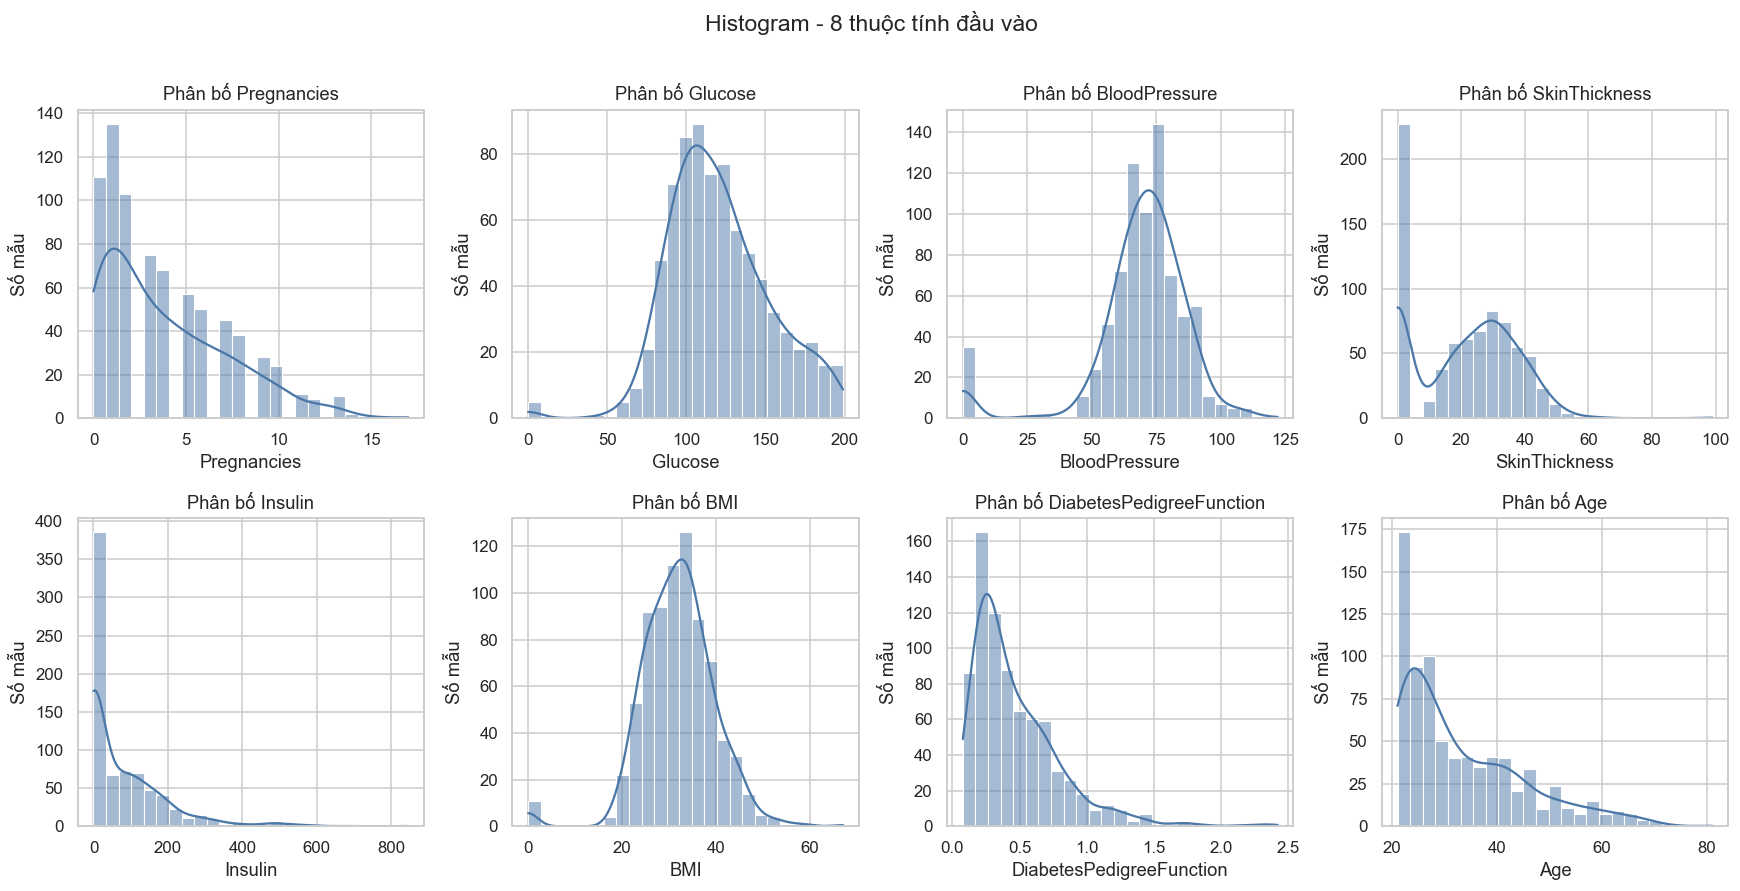

In [20]:

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8)
)

for ax, col in zip(axes.flat, features):
    sns.histplot(
        data=df,
        x=col,
        bins=25,
        kde=True,
        ax=ax,
        color="#4C78A8"
    )

    ax.set_title(f"Phân bố {col}")
    ax.set_ylabel("Số mẫu")

plt.suptitle(
    "Histogram - 8 thuộc tính đầu vào",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()


## Nhận xét biểu đồ Histogram
#### Quan sát các biểu đồ Histogram cho thấy:

- Insulin có phân bố lệch phải rõ rệt và tập trung nhiều giá trị tại 0.
- DiabetesPedigreeFunction có phân bố lệch phải, phần lớn quan sát tập trung ở các giá trị thấp.
- Age có xu hướng lệch phải, tập trung nhiều ở nhóm tuổi trẻ hơn.
- Glucose có phân bố tương đối tập trung quanh vùng giá trị trung tâm nhưng xuất hiện một số giá trị 0 bất thường.
- SkinThickness có nhiều giá trị 0, làm ảnh hưởng đến hình dạng phân bố.

#### Nhìn chung, các thuộc tính có hình dạng phân bố khác nhau và không thể giả định tất cả đều tuân theo phân bố chuẩn.

## 9. Phân tích dữ liệu bằng boxplot

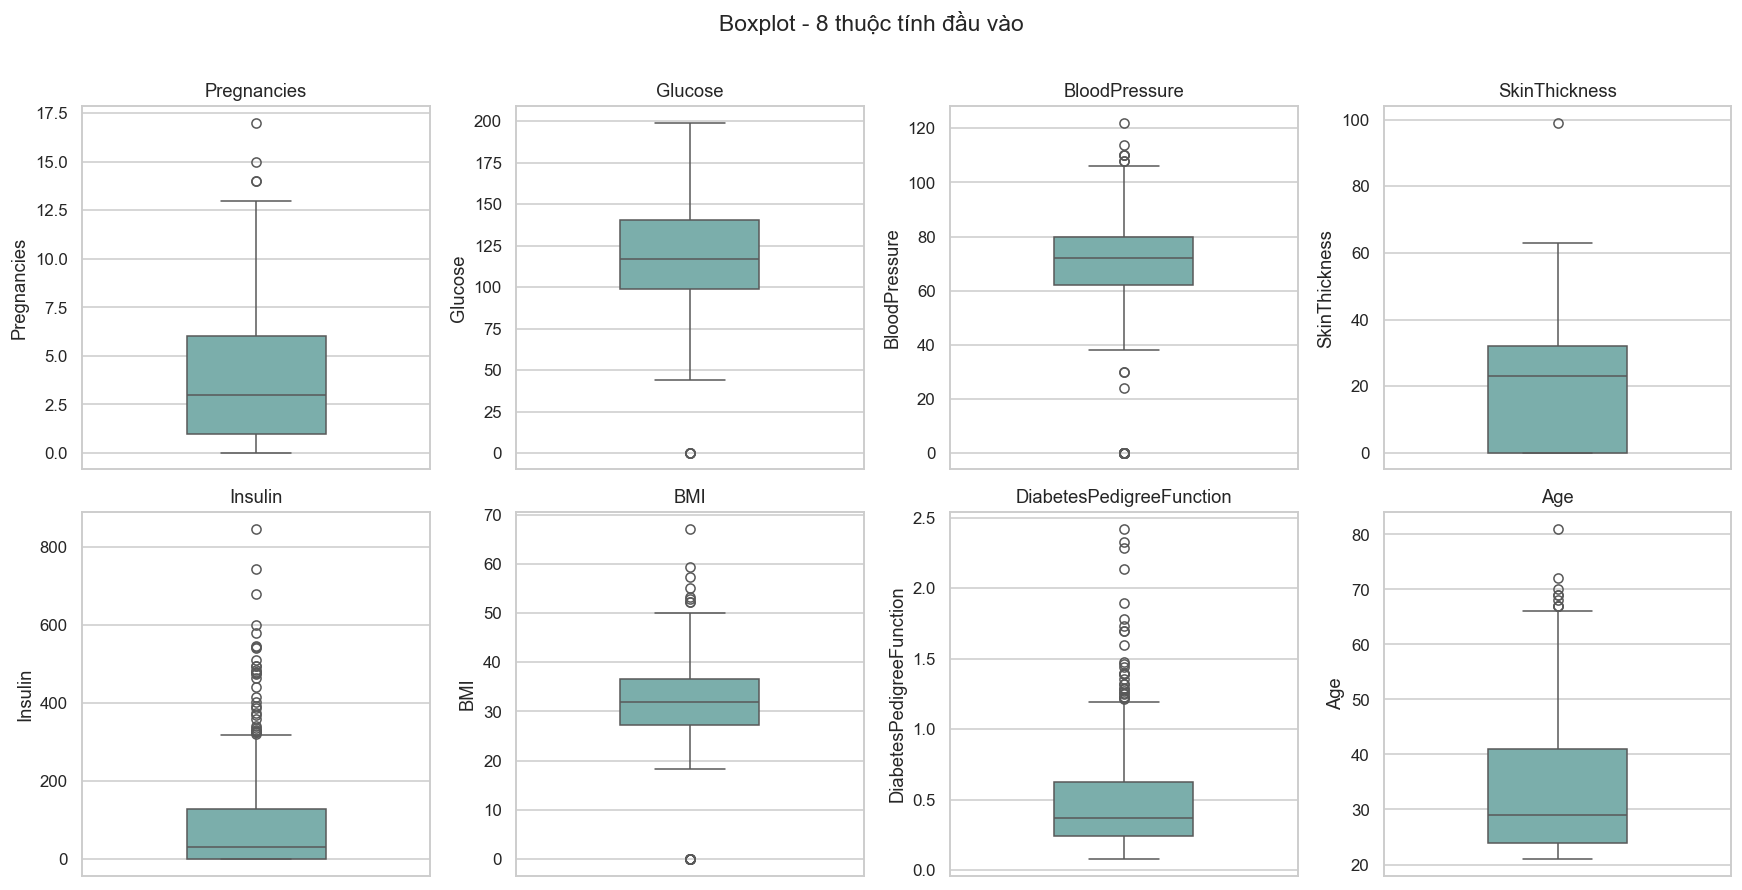

In [21]:

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8)
)

for ax, col in zip(axes.flat, features):
    sns.boxplot(
        y=df[col],
        ax=ax,
        color="#72B7B2",
        width=0.4
    )

    ax.set_title(col)
    ax.set_xlabel("")

plt.suptitle(
    "Boxplot - 8 thuộc tính đầu vào",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()


## 10. Phát hiện giá trị ngoại lai bằng IQR

In [22]:

q1 = X.quantile(0.25)
q3 = X.quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_count = (
    X.lt(lower).sum() +
    X.gt(upper).sum()
)

outlier_table = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Cận dưới": lower,
    "Cận trên": upper,
    "Số ngoại lai (IQR)": outlier_count,
    "Tỷ lệ (%)": (
        outlier_count / len(df) * 100
    )
})

display(outlier_table.round(3))


,Q1,Q3,IQR,Cận dưới,Cận trên,Số ngoại lai (IQR),Tỷ lệ (%)
Pregnancies,1.000,6.000,5.000,-6.500,13.500,4,0.521
Glucose,99.000,140.250,41.250,37.125,202.125,5,0.651
BloodPressure,62.000,80.000,18.000,35.000,107.000,45,5.859
SkinThickness,0.000,32.000,32.000,-48.000,80.000,1,0.130
Insulin,0.000,127.250,127.250,-190.875,318.125,34,4.427
BMI,27.300,36.600,9.300,13.350,50.550,19,2.474
DiabetesPedigreeFunction,0.244,0.626,0.382,-0.330,1.200,29,3.776
Age,24.000,41.000,17.000,-1.500,66.500,9,1.172


## Nhận xét kết quả Boxplot và IQR
#### Kết quả cho thấy một số thuộc tính xuất hiện nhiều quan sát ngoại lai theo quy tắc 1,5 × IQR.

Cụ thể:
- BloodPressure có 45 quan sát bị gắn cờ.
- Insulin có 34 quan sát bị gắn cờ.
- DiabetesPedigreeFunction có 29 quan sát bị gắn cờ.

#### Các quan sát này có thể là giá trị đặc biệt hoặc phản ánh sự phân tán tự nhiên của dữ liệu.

#### Do mục tiêu của bài là thống kê mô tả, các giá trị ngoại lai được giữ nguyên để phân tích thay vì loại bỏ tự động.

## 11. Phân tích thống kê theo hai nhóm Outcome

In [23]:

compare_cols = [
    "Glucose",
    "BMI",
    "Age",
    "BloodPressure",
    "Insulin"
]

grouped = df.groupby("Outcome")[
    compare_cols
].agg([
    "count",
    "mean",
    "median",
    "std"
])

display(grouped.round(2))


Glucose                         BMI                       Age                      BloodPressure         \
          count    mean median    std count   mean median   std count   mean median    std         count   mean   
Outcome                                                                                                           
0           500  109.98  107.0  26.14   500  30.30  30.05  7.69   500  31.19   27.0  11.67           500  68.18   
1           268  141.26  140.0  31.94   268  35.14  34.25  7.26   268  37.07   36.0  10.97           268  70.82   

                      Insulin                         
        median    std   count    mean median     std  
Outcome                                               
0         70.0  18.06     500   68.79   39.0   98.87  
1         74.0  21.49     268  100.34    0.0  138.69

## 12. So sánh Glucose và BMI theo Outcome bằng boxplot

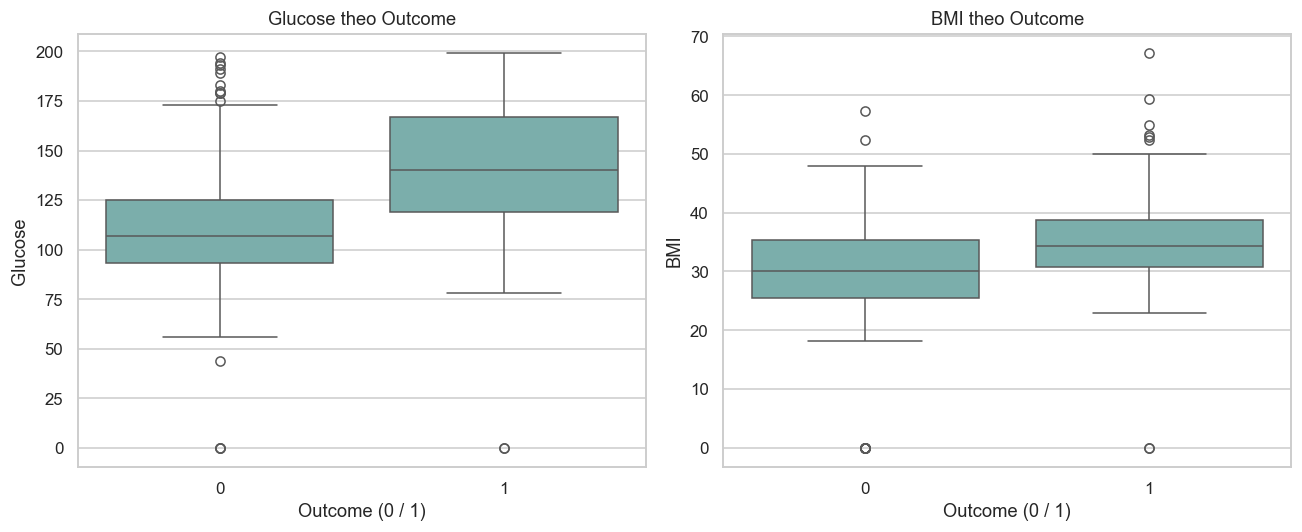

In [24]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, col in zip(
    axes,
    ["Glucose", "BMI"]
):
    sns.boxplot(
        data=df,
        x="Outcome",
        y=col,
        ax=ax,
        color="#72B7B2"
    )

    ax.set_title(f"{col} theo Outcome")
    ax.set_xlabel("Outcome (0 / 1)")

plt.tight_layout()
plt.show()


## Nhận xét thống kê theo Outcome
#### Kết quả thống kê cho thấy sự khác biệt giữa hai nhóm Outcome.

**Glucose:**
- Outcome = 0: Mean khoảng 109,98.
- Outcome = 1: Mean khoảng 141,26.

**BMI:**
- Outcome = 0: Mean khoảng 30,30.
- Outcome = 1: Mean khoảng 35,14.

#### Nhóm Outcome = 1 có giá trị trung bình Glucose và BMI cao hơn nhóm Outcome = 0 trong dataset.

#### Điều này cho thấy các thuộc tính có phân bố khác nhau giữa hai nhóm.

#### Tuy nhiên, đây chỉ là kết quả thống kê mô tả, không chứng minh mối quan hệ nhân quả.

## 13. Kết luận và hạn chế
### 13.1 Kết luận 
Qua quá trình thống kê mô tả trên tập dữ liệu Pima Indians Diabetes, có thể rút ra các kết luận:

**1. Đặc điểm dữ liệu**

Dataset gồm 768 mẫu và 9 thuộc tính, trong đó có 8 thuộc tính đầu vào và 1 nhãn Outcome.

Dữ liệu không chứa NaN và không có dòng trùng lặp hoàn toàn.

**2. Chất lượng dữ liệu**

Một số thuộc tính như Insulin, SkinThickness, Glucose và BloodPressure xuất hiện giá trị 0 bất thường.

Đặc biệt, Insulin có 374 giá trị 0 và SkinThickness có 227 giá trị 0.

Các giá trị này cần được lưu ý khi diễn giải kết quả thống kê.

**3. Kết quả thống kê mô tả**

Bài thực hành đã tính toán đầy đủ:

- Mean, Median, Mode.
- Variance, Standard Deviation.
- Min, Max, Range.
- Percentile 60%.
- Q1, Q2, Q3 và IQR.

Kết quả cho thấy các thuộc tính có mức độ phân tán và hình dạng phân bố khác nhau.

**4. Kết quả trực quan hóa**

Histogram giúp quan sát hình dạng phân bố và xu hướng lệch của các thuộc tính.

Boxplot giúp xác định các quan sát ngoại lai theo quy tắc IQR.

**5. Phân tích theo Outcome**

Kết quả thống kê theo hai nhóm Outcome cho thấy các thuộc tính như Glucose và BMI có sự khác biệt về giá trị trung bình.

### 13.2 Hạn chế
- Dataset chứa nhiều giá trị 0 có khả năng không hợp lệ.
- Các giá trị ngoại lai chưa được xác minh về mặt dữ liệu.
- Kết quả phân tích chỉ mang tính thống kê mô tả.
- Chưa thực hiện xây dựng mô hình dự đoán.